<a href="https://colab.research.google.com/github/Aryan-yadav7/ML_Learning/blob/main/k_means_iris.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

In [2]:
iris = load_iris(as_frame=True)
df = iris.data.copy()
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


In [3]:
print('Dataset shape:', df.shape)
print('\nColumn names:')
print(df.columns.tolist())
print('\nMissing values per column:')
print(df.isnull().sum())
df.describe()

Dataset shape: (150, 4)

Column names:
['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']

Missing values per column:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
dtype: int64


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


In [4]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df)
print('Scaled data shape:', X_scaled.shape)

Scaled data shape: (150, 4)


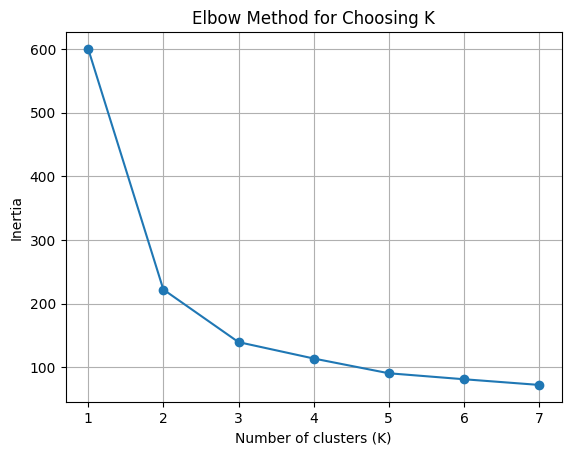

In [12]:
#Choose the \(K\) near the point where the decrease starts slowing down — the “elbow.”
inertia_values = []
k_values = range(1, 8)

for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X_scaled)
    inertia_values.append(model.inertia_)

plt.plot(list(k_values), inertia_values, marker='o')
plt.xlabel('Number of clusters (K)')
plt.ylabel('Inertia')
plt.title('Elbow Method for Choosing K')
plt.xticks(list(k_values))
plt.grid(True)
plt.show()

In [6]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df['Cluster'] = kmeans.fit_predict(X_scaled)
df.head(10)

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),Cluster
0,5.1,3.5,1.4,0.2,1
1,4.9,3.0,1.4,0.2,1
2,4.7,3.2,1.3,0.2,1
3,4.6,3.1,1.5,0.2,1
4,5.0,3.6,1.4,0.2,1
5,5.4,3.9,1.7,0.4,1
6,4.6,3.4,1.4,0.3,1
7,5.0,3.4,1.5,0.2,1
8,4.4,2.9,1.4,0.2,1
9,4.9,3.1,1.5,0.1,1


In [7]:
print('Number of samples in each cluster:')
print(df['Cluster'].value_counts().sort_index())

Number of samples in each cluster:
Cluster
0    53
1    50
2    47
Name: count, dtype: int64


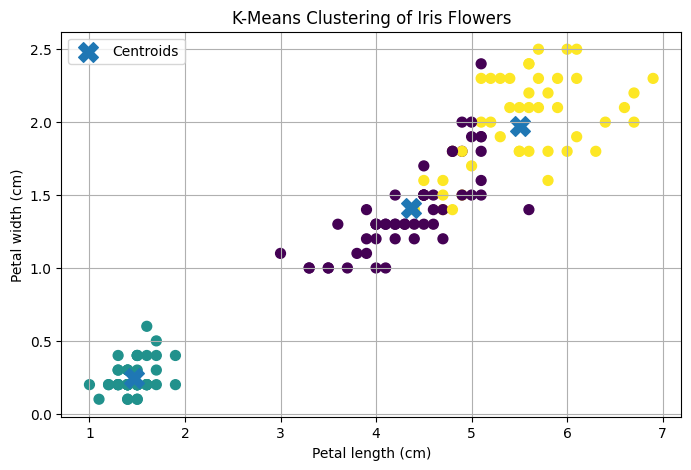

In [8]:
plt.figure(figsize=(8, 5))
plt.scatter(
    df['petal length (cm)'],
    df['petal width (cm)'],
    c=df['Cluster'],
    cmap='viridis',
    s=50
)

# Convert the model's cluster centers back to the original measurement scale
centers_original = scaler.inverse_transform(kmeans.cluster_centers_)
petal_length_index = list(df.columns.drop('Cluster')).index('petal length (cm)')
petal_width_index = list(df.columns.drop('Cluster')).index('petal width (cm)')

plt.scatter(
    centers_original[:, petal_length_index],
    centers_original[:, petal_width_index],
    marker='X',
    s=200,
    label='Centroids'
)
plt.xlabel('Petal length (cm)')
plt.ylabel('Petal width (cm)')
plt.title('K-Means Clustering of Iris Flowers')
plt.legend()
plt.grid(True)
plt.show()

In [9]:
df.head(15)

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),Cluster
0,5.1,3.5,1.4,0.2,1
1,4.9,3.0,1.4,0.2,1
2,4.7,3.2,1.3,0.2,1
3,4.6,3.1,1.5,0.2,1
4,5.0,3.6,1.4,0.2,1
5,5.4,3.9,1.7,0.4,1
6,4.6,3.4,1.4,0.3,1
7,5.0,3.4,1.5,0.2,1
8,4.4,2.9,1.4,0.2,1
9,4.9,3.1,1.5,0.1,1


In [11]:

import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)
from scipy.optimize import linear_sum_assignment

# Actual species labels
y_true = iris.target

# Cluster labels generated by K-Means
y_cluster = df["Cluster"]

# Match cluster IDs with actual species labels
table = pd.crosstab(y_cluster, y_true).reindex(
    index=range(3),
    columns=range(3),
    fill_value=0
)

row_ind, col_ind = linear_sum_assignment(-table.to_numpy())

cluster_map = dict(zip(row_ind, col_ind))
y_pred = y_cluster.map(cluster_map)

# Calculate evaluation metrics
print("Accuracy:", round(accuracy_score(y_true, y_pred), 4))
print("Precision:", round(
    precision_score(y_true, y_pred, average="weighted", zero_division=0), 4
))
print("Recall:", round(
    recall_score(y_true, y_pred, average="weighted", zero_division=0), 4
))
print("F1-Score:", round(
    f1_score(y_true, y_pred, average="weighted", zero_division=0), 4
))

# Classification report
print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    target_names=iris.target_names,
    zero_division=0
))

# Confusion matrix
print("Confusion Matrix:")
print(confusion_matrix(y_true, y_pred))


Accuracy: 0.8333
Precision: 0.8339
Recall: 0.8333
F1-Score: 0.8332

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        50
  versicolor       0.74      0.78      0.76        50
   virginica       0.77      0.72      0.74        50

    accuracy                           0.83       150
   macro avg       0.83      0.83      0.83       150
weighted avg       0.83      0.83      0.83       150

Confusion Matrix:
[[50  0  0]
 [ 0 39 11]
 [ 0 14 36]]
